In [2]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----------- ---------------------------- 2.6/9.5 MB 12.9 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.5 MB 14.8 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 16.9 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 14.7 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 17.8 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ------ --------------------------------- 1/6 [kiwisolver]
   ------------- -------------------------- 2/


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# step 1: Imports and paths 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
# Detect project root
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd

CLEAN_PATH = PROJECT_ROOT / "data" / "cleaned" / "adult_cleaned.csv"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Cleaned dataset exists:", CLEAN_PATH.exists())

Project root: d:\VS Code\Projects\python\Internship
Cleaned dataset exists: True


In [ ]:
# step 2: Load the cleaned dataset

if not CLEAN_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {CLEAN_PATH}\n"
        "Run the Day 1 cleaning notebook first."
    )

df = pd.read_csv(CLEAN_PATH, dtype={"zip_code": "string"})

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (32561, 16)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,zip_code
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,93810
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,24592
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,13278
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,46048
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,42098


In [6]:
# step 3: Structure and data quality

df.info()

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
display(df.nunique().sort_values())

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  str   
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  str   
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  str   
 6   occupation      30718 non-null  str   
 7   relationship    32561 non-null  str   
 8   race            32561 non-null  str   
 9   sex             32561 non-null  str   
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  31978 non-null  str   
 14  income          32561 non-null  str   
 15  zip_code        32561 non-null  string
dtypes: int64(6), str(9), string(1)
memory usage: 6.6 MB

Missing values:


occupation        1843
workclass         1836
native_country     583
fnlwgt               0
education            0
education_num        0
marital_status       0
age                  0
relationship         0
race                 0
capital_gain         0
sex                  0
capital_loss         0
hours_per_week       0
income               0
zip_code             0
dtype: int64


Duplicate rows: 0

Unique values per column:


income                2
sex                   2
race                  5
relationship          6
marital_status        7
workclass             8
occupation           14
education            16
education_num        16
native_country       41
age                  73
capital_loss         92
hours_per_week       94
capital_gain        119
fnlwgt            21648
zip_code          27286
dtype: int64

,count,percentage
income,,
<=50K,24720,75.92
>50K,7841,24.08


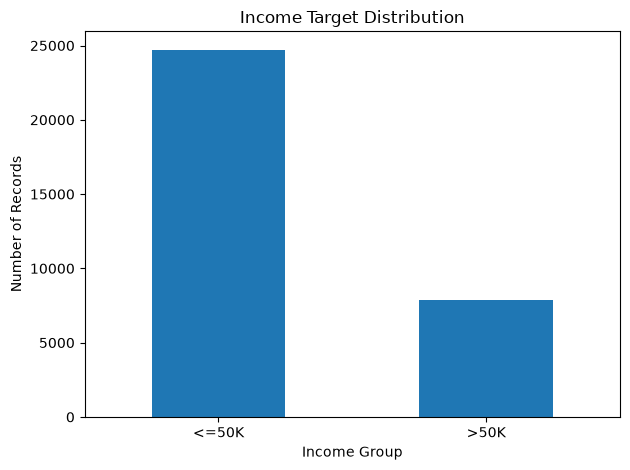

In [7]:
#Step 5 — Income distribution

income_counts = df["income"].value_counts(dropna=False)
income_percent = df["income"].value_counts(
    normalize=True, dropna=False
).mul(100)

income_summary = pd.DataFrame({
    "count": income_counts,
    "percentage": income_percent.round(2)
})

display(income_summary)

income_counts.plot(kind="bar", rot=0)
plt.title("Income Target Distribution")
plt.xlabel("Income Group")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "income_distribution.png", dpi=150)
plt.show()

count    32561.000000
mean        38.581647
std         13.640433
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64


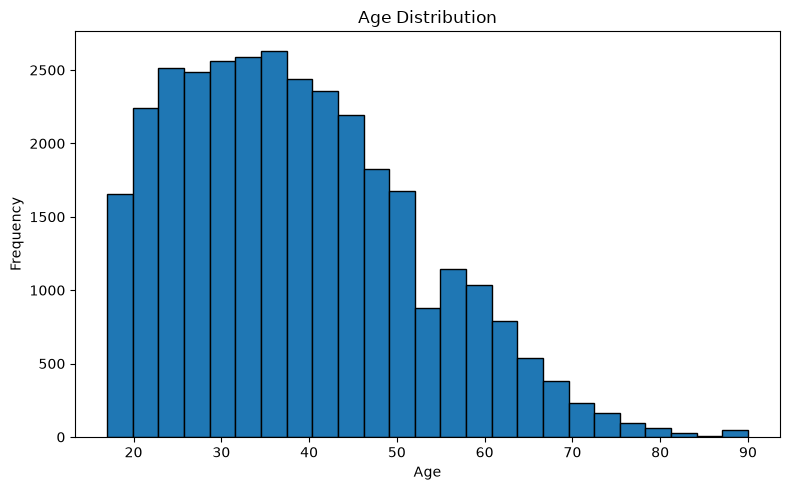

In [8]:
#Step 5 — Age distribution

print(df["age"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["age"].dropna(), bins=25, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "age_distribution.png", dpi=150)
plt.show()

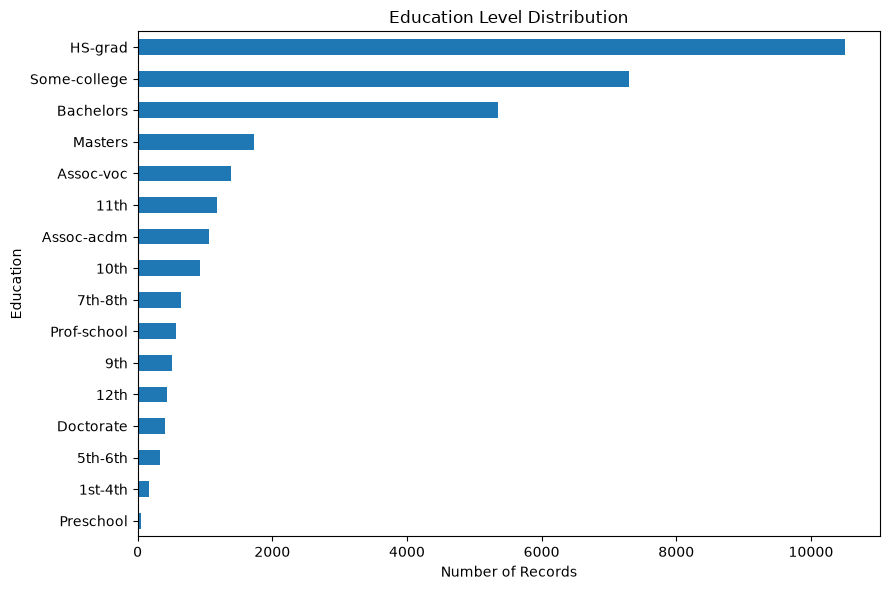

In [9]:
# Step 6 — Education distribution

education_counts = df["education"].value_counts().sort_values()

education_counts.plot(kind="barh", figsize=(9, 6))
plt.title("Education Level Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Education")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "education_distribution.png", dpi=150)
plt.show()

count    32561.000000
mean        40.437456
std         12.347429
min          1.000000
25%         40.000000
50%         40.000000
75%         45.000000
max         99.000000
Name: hours_per_week, dtype: float64


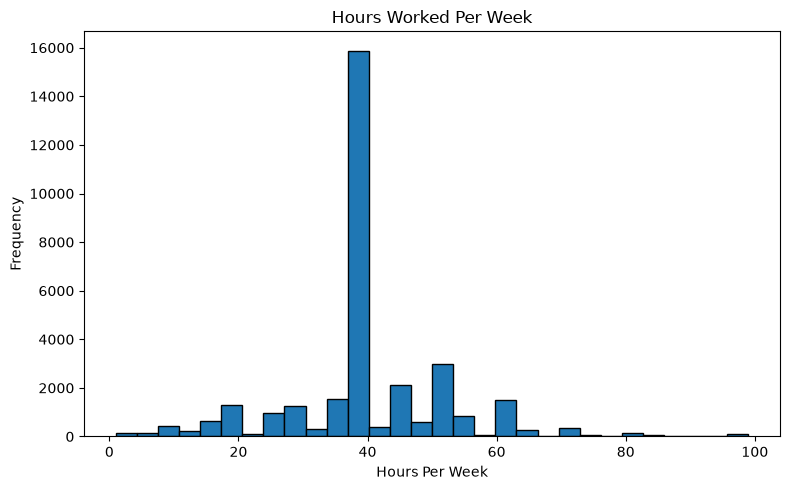

In [11]:
# Step 7 — Working hours

print(df["hours_per_week"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["hours_per_week"].dropna(), bins=30, edgecolor="black")
plt.title("Hours Worked Per Week")
plt.xlabel("Hours Per Week")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "hours_per_week_distribution.png", dpi=150)
plt.show()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
age,1.00,-0.08,0.04,0.08,0.06,0.07
fnlwgt,-0.08,1.00,-0.04,0.00,-0.01,-0.02
education_num,0.04,-0.04,1.00,0.12,0.08,0.15
capital_gain,0.08,0.00,0.12,1.00,-0.03,0.08
capital_loss,0.06,-0.01,0.08,-0.03,1.00,0.05
hours_per_week,0.07,-0.02,0.15,0.08,0.05,1.00


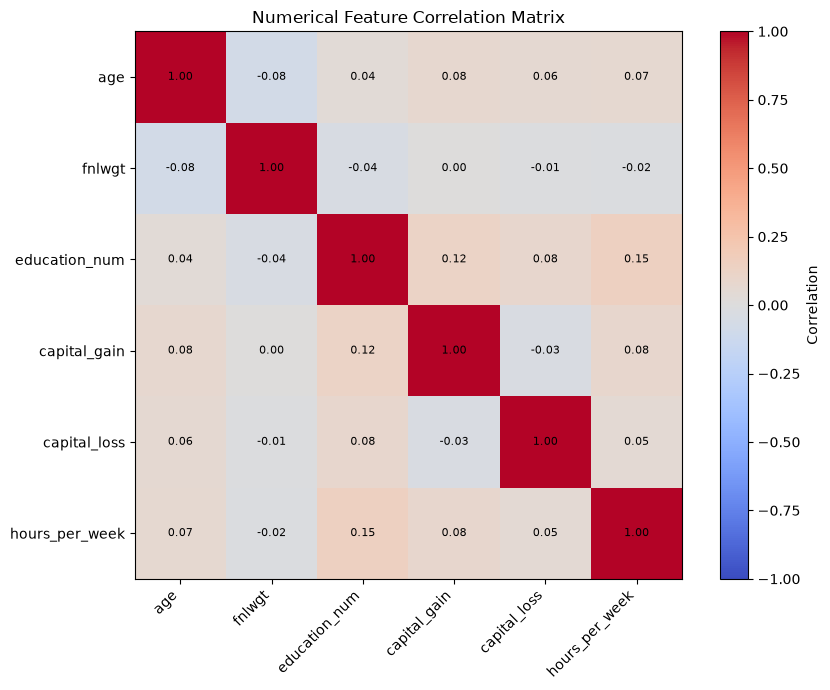

In [13]:
# step 8 — Numerical feature correlations

numeric_cols = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week"
]

correlation = df[numeric_cols].corr()

display(correlation.round(2))

plt.figure(figsize=(9, 7))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha="right")
plt.yticks(range(len(numeric_cols)), numeric_cols)

for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_matrix.png", dpi=150)
plt.show()

In [14]:
# Step 9 - Privacy-relevant columns

privacy_columns = [
    "age",
    "sex",
    "race",
    "native_country",
    "marital_status",
    "occupation",
    "zip_code"
]

privacy_summary = pd.DataFrame({
    "data_type": df[privacy_columns].dtypes.astype(str),
    "unique_values": df[privacy_columns].nunique(dropna=False),
    "missing_values": df[privacy_columns].isna().sum()
})

display(privacy_summary)

,data_type,unique_values,missing_values
age,int64,73,0
sex,str,2,0
race,str,5,0
native_country,str,42,583
marital_status,str,7,0
occupation,str,15,1843
zip_code,string,27286,0


In [15]:
# step 10 - Save a short EDA summary

summary = f"""# Day 2: Exploratory Data Analysis

## Dataset overview
- Rows: {df.shape[0]}
- Columns: {df.shape[1]}
- Duplicate rows: {df.duplicated().sum()}
- Total missing cells: {int(df.isna().sum().sum())}

## Target distribution
{income_summary.to_string()}

## Numerical summary
{df[numeric_cols].describe().round(2).to_string()}

## Notes
- ZIP code was added separately and should not be treated as verified geographic data
  unless its provenance is established.
- Correlation indicates association, not causation.
"""

report_path = PROJECT_ROOT / "report" / "Day2_EDA_Summary.txt"
report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(summary, encoding="utf-8")

print("EDA summary saved to:", report_path)
print("Charts saved to:", FIGURES_DIR)

EDA summary saved to: d:\VS Code\Projects\python\Internship\report\Day2_EDA_Summary.txt
Charts saved to: d:\VS Code\Projects\python\Internship\figures
